# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [Harun Yahya]
- **Email:** [yahya.24044@student.unud.ac.id]
- **ID Dicoding:** [ds014b6y0721]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** **Pertanyaan 1:** Bagaimana perkembangan jumlah pesanan yang berhasil diselesaikan (*delivered orders*) dan total nilai penjualan produk (*product sales value*) secara bulanan pada E-Commerce Olist selama periode September 2016 hingga Agustus 2018, serta pada bulan apa penjualan mencapai nilai tertinggi dan terendah?
- **Pertanyaan 2:** Bagaimana persentase keterlambatan pengiriman pesanan dan rata-rata durasi keterlambatan berdasarkan negara bagian (state) pelanggan di Brasil selama periode September 2016 hingga Oktober 2018, serta wilayah mana yang memiliki performa pengiriman paling rendah?

## Import Semua Packages/Library yang Digunakan

In [2]:
# Import library untuk pengolahan data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Import library tambahan
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.style.use('default')

# Menampilkan seluruh kolom saat eksplorasi DataFrame
pd.set_option('display.max_columns', None)

print("Libraries berhasil di-import!")

Libraries berhasil di-import!


## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
# Load dataset
customers_df = pd.read_csv('customers_dataset.csv')
geolocation_df = pd.read_csv('geolocation_dataset.csv')
order_items_df = pd.read_csv('order_items_dataset.csv')
order_payments_df = pd.read_csv('order_payments_dataset.csv')
order_reviews_df = pd.read_csv('order_reviews_dataset.csv')
orders_df = pd.read_csv('orders_dataset.csv')
category_translation_df = pd.read_csv('product_category_name_translation.csv')
products_df = pd.read_csv('products_dataset.csv')
sellers_df = pd.read_csv('sellers_dataset.csv')

print("Seluruh dataset berhasil dimuat!")

Seluruh dataset berhasil dimuat!


In [4]:
datasets = {
    'Customers': customers_df,
    'Geolocation': geolocation_df,
    'Order Items': order_items_df,
    'Order Payments': order_payments_df,
    'Order Reviews': order_reviews_df,
    'Orders': orders_df,
    'Category Translation': category_translation_df,
    'Products': products_df,
    'Sellers': sellers_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Customers: 99,441 rows, 5 columns
Geolocation: 1,000,163 rows, 5 columns
Order Items: 112,650 rows, 7 columns
Order Payments: 103,886 rows, 5 columns
Order Reviews: 99,224 rows, 7 columns
Orders: 99,441 rows, 8 columns
Category Translation: 71 rows, 2 columns
Products: 32,951 rows, 9 columns
Sellers: 3,095 rows, 4 columns


In [5]:
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    display(df.head())


===== Customers =====


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



===== Geolocation =====


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



===== Order Items =====


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (8 outputs left out)


===== Products =====


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



===== Sellers =====


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


**Insight:** (Opsional)
- Dataset E-Commerce Olist terdiri dari sembilan file CSV yang memiliki informasi berbeda dan saling berhubungan melalui beberapa kolom identifikasi, seperti order_id, customer_id, product_id, dan seller_id.
- Dataset orders digunakan sebagai sumber informasi utama mengenai transaksi dan waktu pemesanan, sedangkan order_items digunakan untuk menghitung nilai penjualan produk. Dataset customers digunakan untuk memperoleh informasi wilayah pelanggan.
- Dataset geolocation, products, sellers, order_payments, dan order_reviews menyediakan informasi pendukung yang dapat digunakan untuk eksplorasi dan pemeriksaan kualitas data.

### Assessing Data

#### Identifying ... problem

In [6]:
# Memeriksa jumlah missing values pada setiap dataset

for name, df in datasets.items():
    print(f"\n===== {name} =====")

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(missing)
    else:
        print("Tidak ditemukan missing values.")


===== Customers =====
Tidak ditemukan missing values.

===== Geolocation =====
Tidak ditemukan missing values.

===== Order Items =====
Tidak ditemukan missing values.

===== Order Payments =====
Tidak ditemukan missing values.

===== Order Reviews =====
review_comment_title      87656
review_comment_message    58247
dtype: int64

===== Orders =====
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

===== Category Translation =====
Tidak ditemukan missing values.

===== Products =====
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

===== Sellers =====
Tidak ditemukan missing values.


In [7]:
# Memeriksa jumlah data duplikat pada setiap dataset

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum():,} duplicate rows")

Customers: 0 duplicate rows
Geolocation: 261,831 duplicate rows
Order Items: 0 duplicate rows
Order Payments: 0 duplicate rows
Order Reviews: 0 duplicate rows
Orders: 0 duplicate rows
Category Translation: 0 duplicate rows
Products: 0 duplicate rows
Sellers: 0 duplicate rows


In [8]:
# Memeriksa tipe data setiap kolom

for name, df in datasets.items():
    print(f"\n===== {name} =====")
    print(df.dtypes)


===== Customers =====
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

===== Geolocation =====
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

===== Order Items =====
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

===== Order Payments =====
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

===== Order Reviews =====
review_id                  object
order_id                   object
r

In [9]:
# Memeriksa periode transaksi

orders_df['order_purchase_timestamp'] = pd.to_datetime(
    orders_df['order_purchase_timestamp'],
    errors='coerce'
)

print("Tanggal transaksi paling awal:")
print(orders_df['order_purchase_timestamp'].min())

print("\nTanggal transaksi paling akhir:")
print(orders_df['order_purchase_timestamp'].max())

Tanggal transaksi paling awal:
2016-09-04 21:15:19

Tanggal transaksi paling akhir:
2018-10-17 17:30:18


In [10]:
# Melihat distribusi status pesanan

display(
    orders_df['order_status']
    .value_counts()
    .reset_index()
    .rename(columns={
        'index': 'order_status',
        'order_status': 'total_orders'
    })
)

,total_orders,count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


**Steps to Take:**
- Missing values pada dataset orders akan dianalisis berdasarkan kolom dan status pesanan. Missing value pada tanggal pengiriman tidak akan diisi dengan nilai buatan karena dapat menyebabkan kesalahan dalam penghitungan durasi pengiriman. Pesanan yang belum memiliki tanggal pengiriman aktual akan dikecualikan dari analisis performa pengiriman.
- Missing values pada dataset products akan diperiksa berdasarkan atribut produk. Data dengan informasi kategori yang tidak tersedia akan dipertahankan dengan penanda kategori tidak diketahui apabila diperlukan dalam analisis.
- Missing values pada dataset order_reviews, khususnya kolom komentar ulasan, tidak akan langsung dihapus karena komentar pelanggan merupakan informasi opsional dan tidak digunakan sebagai dasar utama kedua pertanyaan bisnis.
- Data duplikat pada dataset geolocation akan diidentifikasi dan dihapus agar tidak menyebabkan pengulangan informasi lokasi.
- Kolom tanggal pada dataset orders akan dikonversi ke tipe data datetime untuk mendukung analisis waktu dan perhitungan keterlambatan pengiriman.

**Insight:** (Opsional)
- Dataset geolocation memiliki 261.831 baris duplikat dari total 1.000.163 baris. Duplikasi ini perlu ditangani agar data lokasi tidak berulang.
- Dataset orders memiliki missing values pada kolom order_approved_at, order_delivered_carrier_date, dan order_delivered_customer_date. Missing values pada tanggal pengiriman perlu diperhatikan karena berkaitan dengan status penyelesaian pesanan.
- Dataset products memiliki missing values pada beberapa atribut produk, sedangkan order_reviews memiliki missing values pada kolom komentar ulasan.
- Kolom waktu pada dataset orders memerlukan konversi tipe data menjadi datetime agar dapat digunakan dalam analisis temporal.

### Cleaning Data

#### Fixing ... problem

In [11]:
# Menghapus baris duplikat pada dataset geolocation

geolocation_df_clean = geolocation_df.drop_duplicates().copy()

print("Jumlah data sebelum cleaning:",
      len(geolocation_df))

print("Jumlah data setelah cleaning:",
      len(geolocation_df_clean))

print("Jumlah duplikat tersisa:",
      geolocation_df_clean.duplicated().sum())

Jumlah data sebelum cleaning: 1000163
Jumlah data setelah cleaning: 738332
Jumlah duplikat tersisa: 0


In [12]:
# Mengubah kolom tanggal pada dataset orders

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders_df[col] = pd.to_datetime(
        orders_df[col],
        errors='coerce'
    )

print("Konversi tipe data tanggal selesai.")

display(orders_df[date_columns].dtypes)

Konversi tipe data tanggal selesai.


,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [13]:
# Membuat salinan dataset products

products_df_clean = products_df.copy()

# Mengisi kategori produk yang kosong
products_df_clean['product_category_name'] = (
    products_df_clean['product_category_name']
    .fillna('unknown')
)

print("Missing values kategori produk setelah cleaning:",
      products_df_clean['product_category_name'].isna().sum())

Missing values kategori produk setelah cleaning: 0


In [14]:
# Membuat salinan dataset order_reviews

order_reviews_df_clean = order_reviews_df.copy()

# Mengisi komentar kosong dengan label
# agar data ulasan tetap dapat dipertahankan

review_columns = [
    'review_comment_title',
    'review_comment_message'
]

for col in review_columns:
    order_reviews_df_clean[col] = (
        order_reviews_df_clean[col]
        .fillna('No Comment')
    )

print("Missing values pada kolom komentar setelah cleaning:")

display(
    order_reviews_df_clean[review_columns].isnull().sum()
)

Missing values pada kolom komentar setelah cleaning:


,0
review_comment_title,0
review_comment_message,0


In [15]:
# Membuat salinan dataset orders

orders_df_clean = orders_df.copy()

# Membuat salinan dataset order_items

order_items_df_clean = order_items_df.copy()

# Memeriksa missing values pada kolom penting

print("Missing values pada orders:")
display(orders_df_clean.isnull().sum())

print("\nMissing values pada order_items:")
display(order_items_df_clean.isnull().sum())

Missing values pada orders:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



Missing values pada order_items:


,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


**Insight:** (Opsional)
- Penghapusan data duplikat pada dataset geolocation dilakukan untuk mengurangi pengulangan informasi geografis.
- Konversi tipe data tanggal pada dataset orders memungkinkan perhitungan selisih antara tanggal pengiriman aktual dan tanggal estimasi pengiriman.
- Missing values pada komentar ulasan dan kategori produk ditangani dengan label yang sesuai agar informasi lainnya tetap dapat dipertahankan.
- Missing values pada tanggal pengiriman tidak diisi dengan nilai estimasi atau tanggal buatan karena dapat menghasilkan perhitungan performa pengiriman yang tidak akurat.

## Exploratory Data Analysis (EDA)

### Explore ...

In [16]:
# Mengambil pesanan yang berstatus delivered

delivered_orders = orders_df_clean[
    orders_df_clean['order_status'] == 'delivered'
].copy()

# Menggabungkan data pesanan dengan detail produk

sales_df = pd.merge(
    delivered_orders[
        ['order_id', 'order_purchase_timestamp']
    ],
    order_items_df_clean[
        ['order_id', 'price', 'freight_value']
    ],
    on='order_id',
    how='inner'
)

# Membuat kolom bulan transaksi

sales_df['order_month'] = (
    sales_df['order_purchase_timestamp']
    .dt.to_period('M')
)

print("Data penjualan berhasil digabungkan.")

display(sales_df.head())

Data penjualan berhasil digabungkan.


,order_id,order_purchase_timestamp,price,freight_value,order_month
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,29.99,8.72,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,118.70,22.76,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,159.90,19.22,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,45.00,27.20,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,19.90,8.72,2018-02


In [17]:
# Mengelompokkan penjualan berdasarkan bulan

monthly_sales = sales_df.groupby('order_month').agg(
    total_orders=('order_id', 'nunique'),
    total_sales=('price', 'sum')
).reset_index()

# Mengubah periode menjadi format tanggal

monthly_sales['order_month'] = (
    monthly_sales['order_month'].astype(str)
)

# Menampilkan hasil

display(monthly_sales)

,order_month,total_orders,total_sales
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-12,1,10.90
3,2017-01,750,111798.36
4,2017-02,1653,234223.40
5,2017-03,2546,359198.85
6,2017-04,2303,340669.68
7,2017-05,3546,489338.25
8,2017-06,3135,421923.37
9,2017-07,3872,481604.52


In [29]:
print("===== HIGHEST SALES =====")
print("Bulan:", highest_sales['order_month'])
print("Jumlah pesanan:", highest_sales['total_orders'])
print("Total penjualan: BRL",
      round(highest_sales['total_sales'], 2))

print("\n===== LOWEST SALES =====")
print("Bulan:", lowest_sales['order_month'])
print("Jumlah pesanan:", lowest_sales['total_orders'])
print("Total penjualan: BRL",
      round(lowest_sales['total_sales'], 2))

===== HIGHEST SALES =====
Bulan: 2017-11
Jumlah pesanan: 7289
Total penjualan: BRL 987765.37

===== LOWEST SALES =====
Bulan: 2016-12
Jumlah pesanan: 1
Total penjualan: BRL 10.9


In [28]:
print("Rentang tanggal transaksi delivered:")

print(
    "Tanggal awal:",
    delivered_orders['order_purchase_timestamp'].min()
)

print(
    "Tanggal akhir:",
    delivered_orders['order_purchase_timestamp'].max()
)

print("\nRentang bulan pada data penjualan:")

print("Bulan awal:", monthly_sales['order_month'].min())
print("Bulan akhir:", monthly_sales['order_month'].max())

Rentang tanggal transaksi delivered:
Tanggal awal: 2016-09-15 12:16:38
Tanggal akhir: 2018-08-29 15:00:37

Rentang bulan pada data penjualan:
Bulan awal: 2016-09
Bulan akhir: 2018-08


In [21]:
# Mengambil pesanan yang memiliki tanggal pengiriman aktual
# dan tanggal estimasi pengiriman

delivery_df = orders_df_clean[
    (orders_df_clean['order_status'] == 'delivered') &
    (orders_df_clean['order_delivered_customer_date'].notna()) &
    (orders_df_clean['order_estimated_delivery_date'].notna())
].copy()

# Menghitung durasi pengiriman aktual

delivery_df['delivery_duration'] = (
    delivery_df['order_delivered_customer_date'] -
    delivery_df['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Menghitung selisih antara tanggal aktual dan estimasi

delivery_df['delivery_delay'] = (
    delivery_df['order_delivered_customer_date'] -
    delivery_df['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Menentukan status keterlambatan

delivery_df['is_late'] = (
    delivery_df['delivery_delay'] > 0
)

# Menggabungkan data pelanggan untuk mendapatkan state

delivery_df = pd.merge(
    delivery_df,
    customers_df[
        ['customer_id', 'customer_state']
    ],
    on='customer_id',
    how='left'
)

print("Data pengiriman berhasil disiapkan.")

display(delivery_df.head())

Data pengiriman berhasil disiapkan.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_duration,delivery_delay,is_late,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488,False,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729,False,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498,False,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069,False,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171,False,SP


In [22]:
# Mengelompokkan data pengiriman berdasarkan state

delivery_by_state = delivery_df.groupby(
    'customer_state'
).agg(
    total_orders=('order_id', 'nunique'),
    late_orders=('is_late', 'sum'),
    avg_delivery_duration=('delivery_duration', 'mean'),
    avg_delay_days=(
        'delivery_delay',
        lambda x: x[x > 0].mean()
    )
).reset_index()

# Menghitung persentase keterlambatan

delivery_by_state['late_percentage'] = (
    delivery_by_state['late_orders'] /
    delivery_by_state['total_orders'] * 100
)

# Mengurutkan berdasarkan persentase keterlambatan tertinggi

delivery_by_state = delivery_by_state.sort_values(
    'late_percentage',
    ascending=False
)

display(delivery_by_state)

,customer_state,total_orders,late_orders,avg_delivery_duration,avg_delay_days,late_percentage
1,AL,397,95,24.543855,9.246130,23.929471
9,MA,717,141,21.572976,9.970709,19.665272
16,PI,476,76,19.457098,12.298219,15.966387
5,CE,1279,196,21.266579,14.326787,15.324472
24,SE,335,51,21.519788,16.890978,15.223881
4,BA,3256,457,19.335466,11.099223,14.035627
18,RJ,12350,1664,15.309438,12.848692,13.473684
26,TO,274,35,17.658063,5.651584,12.773723
13,PA,946,117,23.772917,12.303485,12.367865
7,ES,1995,244,15.789307,10.596163,12.230576


In [23]:
# Mengidentifikasi wilayah dengan persentase keterlambatan tertinggi

worst_delivery_state = delivery_by_state.iloc[0]

print("Wilayah dengan persentase keterlambatan tertinggi:")
print(worst_delivery_state)

# Menampilkan lima wilayah dengan keterlambatan tertinggi

display(
    delivery_by_state.head(5)
)

Wilayah dengan persentase keterlambatan tertinggi:
customer_state                  AL
total_orders                   397
late_orders                     95
avg_delivery_duration    24.543855
avg_delay_days             9.24613
late_percentage          23.929471
Name: 1, dtype: object


,customer_state,total_orders,late_orders,avg_delivery_duration,avg_delay_days,late_percentage
1,AL,397,95,24.543855,9.246130,23.929471
9,MA,717,141,21.572976,9.970709,19.665272
16,PI,476,76,19.457098,12.298219,15.966387
5,CE,1279,196,21.266579,14.326787,15.324472
24,SE,335,51,21.519788,16.890978,15.223881


**Note:**
- late_percentage dihitung dari jumlah pesanan terlambat dibagi seluruh pesanan delivered yang memenuhi kriteria pengamatan.
- avg_delay_days hanya menghitung pesanan yang benar-benar terlambat.
- avg_delivery_duration menghitung durasi sejak pesanan dibuat sampai diterima pelanggan.
- Wilayah dengan persentase keterlambatan tertinggi belum tentu memiliki jumlah pesanan terlambat terbanyak. Kita akan mempertimbangkan jumlah pesanan ketika menginterpretasikan hasilnya.

**Insight:** (Opsional)
- Berdasarkan hasil pengelompokan transaksi secara bulanan, jumlah pesanan dan total nilai penjualan produk menunjukkan kecenderungan meningkat dari tahun 2017 hingga tahun 2018, meskipun terdapat fluktuasi pada beberapa periode. Nilai penjualan tertinggi tercatat pada November 2017 sebesar BRL 987.765,37 dengan 7.289 pesanan, sedangkan nilai terendah terjadi pada Desember 2016 sebesar BRL 10,90 dengan satu pesanan. Rendahnya nilai penjualan pada Desember 2016 perlu diinterpretasikan secara hati-hati karena jumlah transaksi yang tercatat sangat sedikit.
- Berdasarkan analisis pengiriman berdasarkan negara bagian pelanggan, Alagoas (AL) memiliki persentase keterlambatan tertinggi sebesar 23,93%, dengan 95 pesanan terlambat dari total 397 pesanan yang dianalisis.
- Rata-rata durasi pengiriman di wilayah Alagoas adalah 24,54 hari, sedangkan rata-rata keterlambatan khusus pada pesanan yang terlambat adalah 9,25 hari. Temuan ini menunjukkan adanya perbedaan performa pengiriman antarwilayah yang dapat menjadi dasar evaluasi efektivitas distribusi dan layanan logistik.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
"Bagaimana perkembangan jumlah pesanan yang berhasil diselesaikan (delivered orders) dan total nilai penjualan produk (product sales value) secara bulanan pada E-Commerce Olist selama periode September 2016 hingga Agustus 2018, serta pada bulan apa penjualan mencapai nilai tertinggi dan terendah?"

Analisis visualisasi pertama bertujuan untuk menggambarkan perkembangan performa penjualan E-Commerce Olist berdasarkan jumlah pesanan yang berhasil diselesaikan dan total nilai penjualan produk secara bulanan selama periode September 2016 hingga Agustus 2018.

Visualisasi dilakukan dengan membandingkan total nilai penjualan produk (product sales value) dan jumlah pesanan (delivered orders) pada setiap bulan. Hasil visualisasi digunakan untuk mengidentifikasi tren penjualan, fluktuasi transaksi, serta periode dengan nilai penjualan tertinggi dan terendah.

**Preparing Monthly Sales Data**

In [33]:
# Membuat salinan data penjualan bulanan
visual_sales = monthly_sales.copy()

# Mengubah kolom order_month menjadi period
visual_sales['order_month'] = pd.PeriodIndex(
    visual_sales['order_month'],
    freq='M'
)

# Membuat rentang bulan lengkap
all_months = pd.period_range(
    start='2016-09',
    end='2018-08',
    freq='M'
)

# Melengkapi bulan yang tidak memiliki transaksi
visual_sales = (
    visual_sales
    .set_index('order_month')
    .reindex(all_months, fill_value=0)
    .rename_axis('order_month')
    .reset_index()
)

# Mengubah format bulan menjadi string
visual_sales['order_month'] = (
    visual_sales['order_month'].astype(str)
)

# Menampilkan data
display(visual_sales)

,order_month,total_orders,total_sales
0,2016-09,1,134.97
1,2016-10,265,40325.11
2,2016-11,0,0.00
3,2016-12,1,10.90
4,2017-01,750,111798.36
5,2017-02,1653,234223.40
6,2017-03,2546,359198.85
7,2017-04,2303,340669.68
8,2017-05,3546,489338.25
9,2017-06,3135,421923.37


**Monthly Sales Performance Visualization**

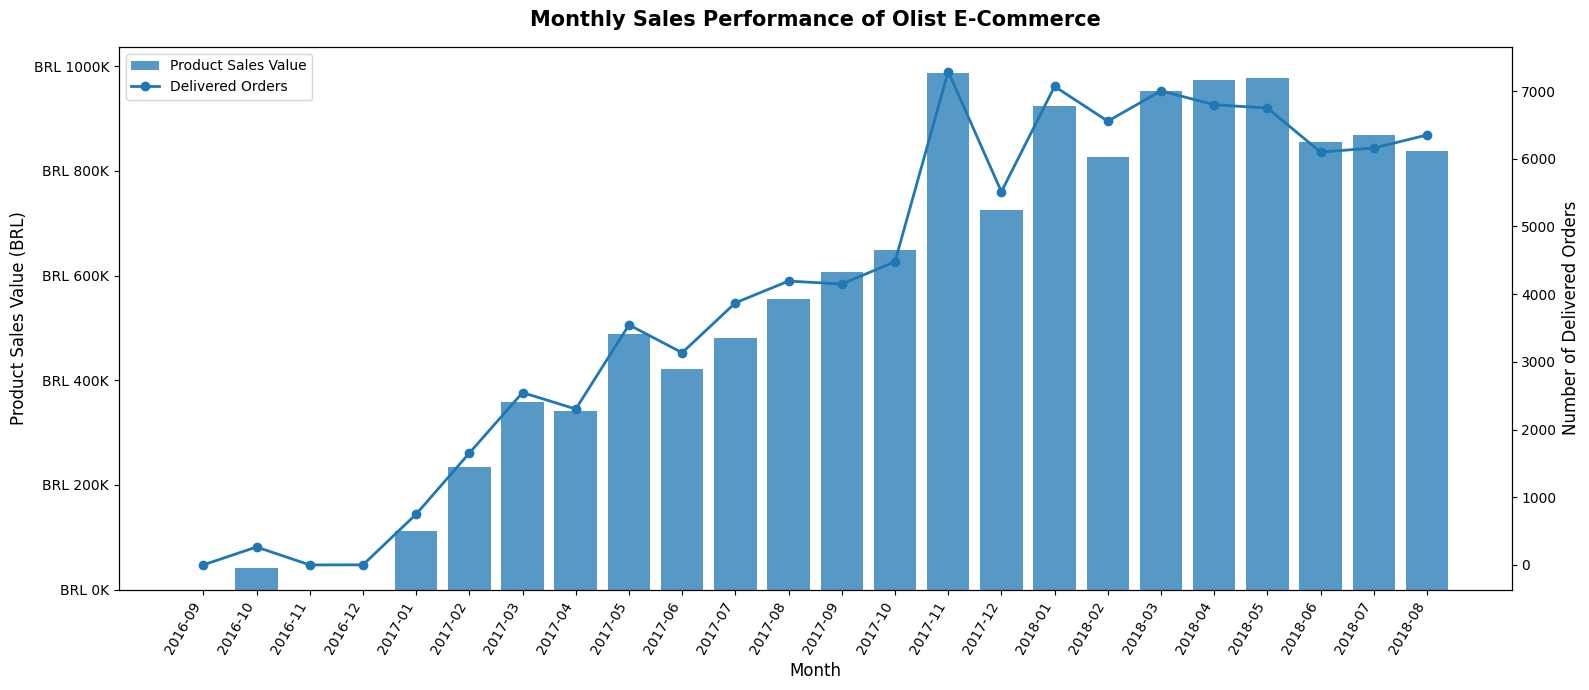

In [34]:
import matplotlib.ticker as mticker

# Membuat figure dan axes
fig, ax1 = plt.subplots(figsize=(16, 7))

x = np.arange(len(visual_sales))

# Grafik batang nilai penjualan
ax1.bar(
    x,
    visual_sales['total_sales'],
    label='Product Sales Value',
    alpha=0.75
)

ax1.set_xlabel('Month', fontsize=12)
ax1.set_ylabel('Product Sales Value (BRL)', fontsize=12)

ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, position: f'BRL {value/1000:.0f}K'
    )
)

ax1.set_xticks(x)
ax1.set_xticklabels(
    visual_sales['order_month'],
    rotation=60,
    ha='right'
)

# Grafik garis jumlah pesanan
ax2 = ax1.twinx()

ax2.plot(
    x,
    visual_sales['total_orders'],
    marker='o',
    linewidth=2,
    label='Delivered Orders'
)

ax2.set_ylabel('Number of Delivered Orders', fontsize=12)

# Judul grafik
plt.title(
    'Monthly Sales Performance of Olist E-Commerce',
    fontsize=15,
    fontweight='bold',
    pad=15
)

# Menggabungkan legenda
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper left'
)

plt.tight_layout()
plt.show()

**Highest and Lowest Monthly Sales**

In [50]:
# Mengidentifikasi penjualan tertinggi
highest_sales = visual_sales.loc[
    visual_sales['total_sales'].idxmax()
]

# Mengidentifikasi penjualan terendah
# hanya pada bulan dengan transaksi
sales_with_transactions = visual_sales[
    visual_sales['total_orders'] > 0
]

lowest_sales = sales_with_transactions.loc[
    sales_with_transactions['total_sales'].idxmin()
]

print("===== HIGHEST SALES =====")
print("Month:", highest_sales['order_month'])
print("Total Orders:", highest_sales['total_orders'])
print("Total Sales: BRL",
      f"{highest_sales['total_sales']:,.2f}")

print("\n===== LOWEST SALES =====")
print("Month:", lowest_sales['order_month'])
print("Total Orders:", lowest_sales['total_orders'])
print("Total Sales: BRL",
      f"{lowest_sales['total_sales']:,.2f}")

===== HIGHEST SALES =====
Month: 2017-11
Total Orders: 7289
Total Sales: BRL 987,765.37

===== LOWEST SALES =====
Month: 2016-12
Total Orders: 1
Total Sales: BRL 10.90


### Pertanyaan 2:
Bagaimana persentase keterlambatan pengiriman pesanan dan rata-rata durasi keterlambatan berdasarkan negara bagian (state) pelanggan di Brasil selama periode pengamatan berdasarkan data pengiriman yang tersedia, serta wilayah mana yang memiliki performa pengiriman paling rendah

Analisis visualisasi kedua bertujuan untuk mengevaluasi performa pengiriman pesanan berdasarkan negara bagian pelanggan di Brasil.

Evaluasi dilakukan dengan membandingkan persentase pesanan yang mengalami keterlambatan dan rata-rata durasi keterlambatan pengiriman pada masing-masing wilayah. Hasil analisis digunakan untuk mengidentifikasi wilayah dengan tingkat keterlambatan tertinggi serta wilayah yang memerlukan perhatian lebih dalam evaluasi operasional logistik.

**Delivery Delay Rate by State**

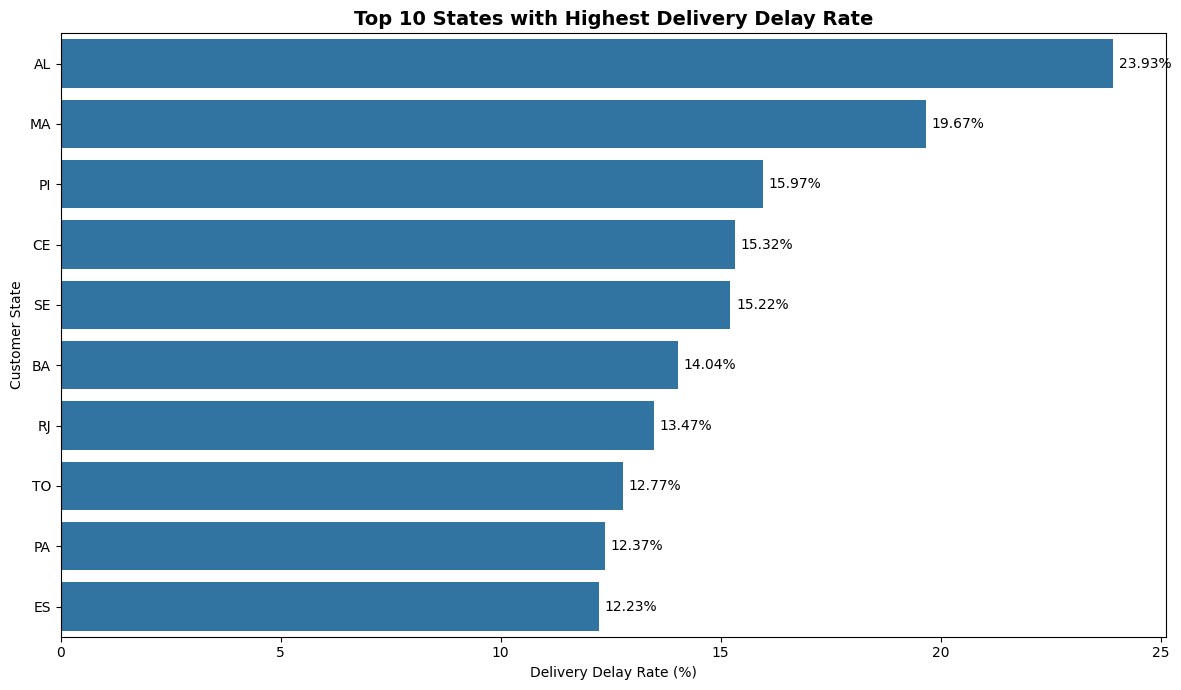

In [36]:
# Memilih wilayah dengan minimal 100 pesanan
delivery_visual = delivery_by_state[
    delivery_by_state['total_orders'] >= 100
].copy()

# Mengurutkan berdasarkan persentase keterlambatan
top_late_states = delivery_visual.sort_values(
    'late_percentage',
    ascending=False
).head(10)

# Membuat visualisasi
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_late_states,
    x='late_percentage',
    y='customer_state'
)

# Menambahkan label angka
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=4
    )

plt.title(
    'Top 10 States with Highest Delivery Delay Rate',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Delivery Delay Rate (%)')
plt.ylabel('Customer State')

plt.tight_layout()
plt.show()

**Average Delivery Delay by State**

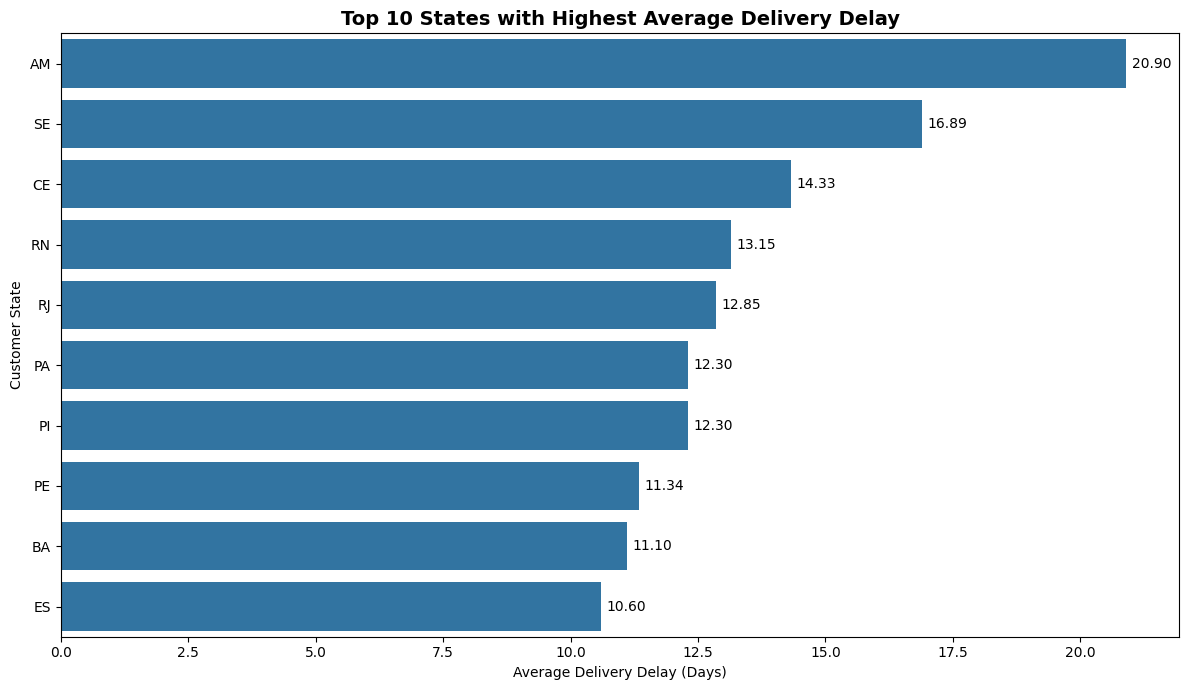

In [37]:
# Mengurutkan wilayah berdasarkan rata-rata keterlambatan
top_avg_delay = (
    delivery_visual
    .dropna(subset=['avg_delay_days'])
    .sort_values(
        'avg_delay_days',
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_avg_delay,
    x='avg_delay_days',
    y='customer_state'
)

# Menambahkan label angka
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=4
    )

plt.title(
    'Top 10 States with Highest Average Delivery Delay',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Average Delivery Delay (Days)')
plt.ylabel('Customer State')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- Visualisasi perkembangan penjualan bulanan menunjukkan adanya kecenderungan peningkatan jumlah pesanan dan total nilai penjualan produk selama periode pengamatan, meskipun terdapat fluktuasi pada beberapa bulan. Puncak penjualan terjadi pada November 2017 dengan total nilai penjualan sebesar BRL 987.765,37 dan 7.289 pesanan. Sebaliknya, nilai penjualan terendah terjadi pada Desember 2016 sebesar BRL 10,90 dengan satu pesanan.

- Hasil visualisasi performa pengiriman menunjukkan adanya variasi persentase keterlambatan antarnegara bagian di Brasil. Alagoas (AL) merupakan wilayah dengan persentase keterlambatan tertinggi sebesar 23,93%, dengan 95 pesanan terlambat dari total 397 pesanan.

- Berdasarkan analisis rata-rata keterlambatan, wilayah dengan durasi keterlambatan tertinggi perlu diperhatikan sebagai salah satu prioritas evaluasi operasional logistik. Hasil ini menunjukkan bahwa evaluasi distribusi perlu mempertimbangkan baik persentase keterlambatan maupun durasi keterlambatan, bukan hanya jumlah pesanan.

## Analisis Lanjutan (Opsional)

### RFM Analysis: Customer Segmentation Based on Purchasing Behavior

Analisis lanjutan pada proyek ini menggunakan metode Recency, Frequency, dan Monetary (RFM) untuk mengidentifikasi karakteristik pelanggan berdasarkan perilaku pembelian mereka.

RFM merupakan metode segmentasi pelanggan yang menggunakan tiga indikator utama, yaitu Recency untuk mengukur jarak waktu sejak transaksi terakhir pelanggan, Frequency untuk menghitung frekuensi transaksi, dan Monetary untuk mengukur total nilai pembelian pelanggan.

Melalui analisis ini, pelanggan akan dikelompokkan berdasarkan skor RFM untuk mengidentifikasi pelanggan dengan aktivitas pembelian tinggi, pelanggan potensial, serta pelanggan yang perlu mendapatkan perhatian lebih melalui strategi retensi.

Dalam analisis ini, transaksi yang digunakan dibatasi pada pesanan berstatus delivered. Nilai Monetary dihitung berdasarkan total harga produk tanpa memasukkan biaya pengiriman.

In [38]:
# Mengambil pesanan delivered
rfm_orders = orders_df_clean[
    orders_df_clean['order_status'] == 'delivered'
].copy()

# Menggabungkan informasi pelanggan unik
rfm_orders = pd.merge(
    rfm_orders,
    customers_df[
        ['customer_id', 'customer_unique_id']
    ],
    on='customer_id',
    how='left'
)

# Menghitung total harga produk setiap pesanan
order_monetary = (
    order_items_df_clean
    .groupby('order_id')['price']
    .sum()
    .reset_index()
)

order_monetary.rename(
    columns={'price': 'Monetary'},
    inplace=True
)

# Menggabungkan nilai transaksi ke data pelanggan
rfm_orders = pd.merge(
    rfm_orders,
    order_monetary,
    on='order_id',
    how='inner'
)

# Memastikan tanggal transaksi valid
rfm_orders = rfm_orders.dropna(
    subset=['order_purchase_timestamp', 'customer_unique_id']
)

display(rfm_orders.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,Monetary
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,19.90


In [39]:
# Menentukan tanggal acuan analisis
reference_date = (
    rfm_orders['order_purchase_timestamp'].max()
    + pd.Timedelta(days=1)
)

# Menghitung Recency, Frequency, dan Monetary
rfm_df = rfm_orders.groupby(
    'customer_unique_id'
).agg(
    Recency=(
        'order_purchase_timestamp',
        lambda x: (reference_date - x.max()).days
    ),
    Frequency=('order_id', 'nunique'),
    Monetary=('Monetary', 'sum')
).reset_index()

# Menampilkan hasil
display(rfm_df.head())

print("Jumlah pelanggan yang dianalisis:",
      rfm_df['customer_unique_id'].nunique())

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00


Jumlah pelanggan yang dianalisis: 93358


In [45]:
# Menghitung Recency Score
# Semakin kecil Recency, semakin tinggi skor

rfm_df['R_Score'] = np.ceil(
    (1 - rfm_df['Recency'].rank(
        method='average',
        pct=True
    )) * 5
).clip(1, 5).astype(int)


# Menghitung Frequency Score berdasarkan jumlah transaksi
# Pelanggan dengan jumlah transaksi sama memperoleh skor sama

rfm_df['F_Score'] = pd.cut(
    rfm_df['Frequency'],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=[1, 2, 3, 4, 5]
).astype(int)


# Menghitung Monetary Score
# Semakin besar Monetary, semakin tinggi skor

rfm_df['M_Score'] = np.ceil(
    rfm_df['Monetary'].rank(
        method='average',
        pct=True
    ) * 5
).clip(1, 5).astype(int)


# Menggabungkan ketiga skor RFM
rfm_df['RFM_Score'] = (
    rfm_df['R_Score'].astype(str) +
    rfm_df['F_Score'].astype(str) +
    rfm_df['M_Score'].astype(str)
)

# Menampilkan hasil
display(rfm_df.head(10))

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,414,Recent Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,411,Recent Customers
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112,Others
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211,Others
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,215,Others
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,4,1,4,414,Recent Customers
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,4,1,1,411,Recent Customers
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,3,1,5,315,Others
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1,1,4,114,Others
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,4,1,3,413,Recent Customers


In [46]:
# Menentukan kondisi segmentasi pelanggan

conditions = [
    # Champions
    (
        (rfm_df['R_Score'] >= 4) &
        (rfm_df['F_Score'] >= 3) &
        (rfm_df['M_Score'] >= 4)
    ),

    # Loyal Customers
    (
        (rfm_df['R_Score'] >= 3) &
        (rfm_df['F_Score'] >= 3) &
        (rfm_df['M_Score'] >= 3)
    ),

    # At Risk
    (
        (rfm_df['R_Score'] <= 2) &
        (rfm_df['F_Score'] >= 3)
    ),

    # Potential Loyalists
    (
        (rfm_df['R_Score'] >= 4) &
        (rfm_df['F_Score'] <= 2) &
        (rfm_df['M_Score'] >= 3)
    ),

    # Recent Customers
    (
        (rfm_df['R_Score'] >= 4) &
        (rfm_df['F_Score'] == 1) &
        (rfm_df['M_Score'] < 3)
    )
]

segment_names = [
    'Champions',
    'Loyal Customers',
    'At Risk',
    'Potential Loyalists',
    'Recent Customers'
]

rfm_df['Customer_Segment'] = np.select(
    conditions,
    segment_names,
    default='Others'
)

display(rfm_df.head(10))

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,414,Potential Loyalists
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,411,Recent Customers
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112,Others
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211,Others
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,215,Others
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,4,1,4,414,Potential Loyalists
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,4,1,1,411,Recent Customers
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,3,1,5,315,Others
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1,1,4,114,Others
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,4,1,3,413,Potential Loyalists


In [47]:
# Membuat ringkasan setiap segmen pelanggan

rfm_summary = rfm_df.groupby(
    'Customer_Segment',
    observed=False
).agg(
    Total_Customers=('customer_unique_id', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Monetary=('Monetary', 'sum')
).reset_index()

# Menghitung persentase pelanggan

rfm_summary['Customer_Percentage'] = (
    rfm_summary['Total_Customers'] /
    rfm_summary['Total_Customers'].sum() * 100
)

# Mengurutkan berdasarkan jumlah pelanggan

rfm_summary = rfm_summary.sort_values(
    'Total_Customers',
    ascending=False
)

display(rfm_summary.round(2))

,Customer_Segment,Total_Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Monetary,Customer_Percentage
3,Others,55934,336.08,1.03,139.05,7777446.15,59.91
4,Potential Loyalists,22706,91.35,1.04,210.42,4777724.66,24.32
5,Recent Customers,14492,89.37,1.00,39.28,569305.23,15.52
1,Champions,114,92.70,3.56,492.78,56177.11,0.12
0,At Risk,69,393.12,3.14,351.61,24261.21,0.07
2,Loyal Customers,43,190.37,3.40,385.67,16583.75,0.05


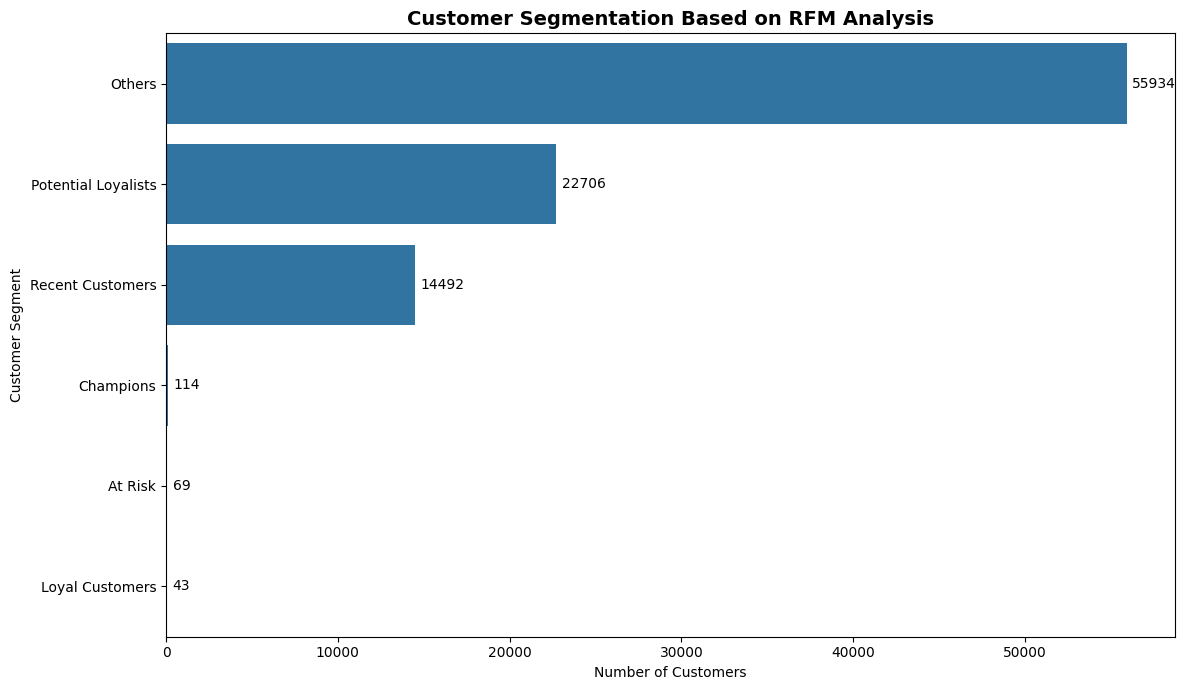

In [48]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=rfm_summary,
    x='Total_Customers',
    y='Customer_Segment'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.0f',
        padding=4
    )

plt.title(
    'Customer Segmentation Based on RFM Analysis',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')

plt.tight_layout()
plt.show()

In [49]:
# Segmen dengan total nilai pembelian terbesar

highest_total_segment = rfm_summary.loc[
    rfm_summary['Total_Monetary'].idxmax()
]

# Segmen dengan rata-rata nilai pembelian terbesar

highest_avg_segment = rfm_summary.loc[
    rfm_summary['Avg_Monetary'].idxmax()
]

print("===== HIGHEST TOTAL MONETARY =====")
display(highest_total_segment.to_frame())

print("\n===== HIGHEST AVERAGE MONETARY =====")
display(highest_avg_segment.to_frame())

===== HIGHEST TOTAL MONETARY =====


,3
Customer_Segment,Others
Total_Customers,55934
Avg_Recency,336.083688
Avg_Frequency,1.028659
Avg_Monetary,139.046844
Total_Monetary,7777446.15
Customer_Percentage,59.913451



===== HIGHEST AVERAGE MONETARY =====


,1
Customer_Segment,Champions
Total_Customers,114
Avg_Recency,92.701754
Avg_Frequency,3.561404
Avg_Monetary,492.781667
Total_Monetary,56177.11
Customer_Percentage,0.122111


**Insight:** (Opsional)

- Berdasarkan hasil RFM Analysis, sebanyak 93.358 pelanggan berhasil dikelompokkan ke dalam enam segmen berdasarkan indikator Recency, Frequency, dan Monetary. Hasil segmentasi menunjukkan bahwa segmen Others merupakan kelompok terbesar, yaitu 55.934 pelanggan (59,91%), diikuti Potential Loyalists sebanyak 22.706 pelanggan (24,32%) dan Recent Customers sebanyak 14.492 pelanggan (15,52%).

- Segmen Champions memiliki rata-rata nilai pembelian tertinggi (*Average Monetary*), yaitu sebesar BRL 492,78 per pelanggan, dengan rata-rata frekuensi pembelian sebanyak 3,56 kali. Meskipun hanya mencakup 114 pelanggan (0,12%), segmen ini menunjukkan kontribusi nilai pembelian yang tinggi pada tingkat individu.

- Segmen Others memiliki total nilai pembelian terbesar (*Total Monetary*), yaitu BRL 7.777.446,15. Hal ini sejalan dengan jumlah anggotanya yang mendominasi keseluruhan pelanggan. Namun, rata-rata nilai pembelian per pelanggan pada segmen ini hanya sebesar BRL 139,05.

- Segmen At Risk terdiri dari 69 pelanggan dengan rata-rata Recency sebesar 393,12 hari dan rata-rata Frequency sebanyak 3,14 kali. Karakteristik ini menunjukkan adanya pelanggan dengan riwayat pembelian berulang yang sudah cukup lama tidak melakukan transaksi sehingga berpotensi menjadi sasaran strategi reaktivasi.

- Hasil segmentasi menunjukkan bahwa karakteristik dan kontribusi pelanggan berbeda antarsegmen. Informasi ini dapat dimanfaatkan untuk menyusun strategi pemasaran yang lebih terarah, seperti mempertahankan pelanggan bernilai tinggi, mendorong pembelian berulang, serta meningkatkan retensi pelanggan.

## Conclusion & Recommendation

**- Conclusion pertanyaan 1:** Penjualan E-Commerce Olist menunjukkan kecenderungan meningkat selama September 2016–Agustus 2018. Penjualan tertinggi terjadi pada November 2017 sebesar BRL 987.765,37, sedangkan penjualan terendah terjadi pada Desember 2016 sebesar BRL 10,90.

**- Conclusion pertanyaan 2** Alagoas (AL) memiliki persentase keterlambatan pengiriman tertinggi sebesar 23,93%, dengan rata-rata keterlambatan 9,25 hari. Hal ini menunjukkan perlunya evaluasi distribusi dan layanan logistik pada wilayah tersebut.

**- Conclusion analisis lanjutan:** Hasil RFM Analysis menunjukkan bahwa segmen Others mendominasi pelanggan sebesar 59,91%, sedangkan Champions memiliki rata-rata nilai pembelian tertinggi sebesar BRL 492,78 per pelanggan.

**Rekomendasi Action Item:**
- Melakukan evaluasi strategi penjualan dan promosi berdasarkan perkembangan transaksi bulanan.
- Mengoptimalkan proses distribusi dan mengevaluasi mitra logistik, khususnya pada wilayah dengan tingkat keterlambatan tinggi.
- Menerapkan strategi pemasaran berdasarkan segmentasi RFM, seperti program loyalitas untuk Champions dan kampanye reaktivasi untuk pelanggan At Risk.